In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_src = r"D:\MSCS Stuff\kisomose\miniiproject 1\mini-projects-OOP\src"
if project_src not in sys.path:
    sys.path.insert(0, project_src)

from taxi_model import Route, solve_supply_demand_equilibrium, MovingAverageForecaster, SimpleExponentialSmoothingForecaster, LinearTrendForecaster

# Data setup
ntinda_passengers = [35, 40, 42, 50, 55, 60, 48, 52, 47, 45]
entebbe_passengers = [60, 58, 65, 70, 72, 80, 75, 68, 66, 64]
mukono_passengers  = [45, 47, 50, 49, 55, 62, 58, 53, 51, 50]

routes = [
    Route("Kampala-Ntinda", ntinda_passengers, 2000.0),
    Route("Kampala-Entebbe", entebbe_passengers, 5000.0),
    Route("Kampala-Mukono", mukono_passengers, 3000.0)
]

summary_records = []
for r in routes:
    stats = r.descriptive_statistics()
    summary_records.append({
        "Route": r.name,
        "Fare (UGX)": r.fare,
        "Total Revenue (UGX)": f"{r.total_revenue():,.2f}",
        "Mean Passengers": round(stats["mean"], 2),
        "Variance": round(stats["variance"], 2),
        "Std Dev": round(stats["stdev"], 2)
    })

print("--- Route Revenue & Descriptive Statistics ---")
print(pd.DataFrame(summary_records).to_string(index=False))

--- Route Revenue & Descriptive Statistics ---
          Route  Fare (UGX) Total Revenue (UGX)  Mean Passengers  Variance  Std Dev
 Kampala-Ntinda      2000.0          948,000.00             47.4     54.27     7.37
Kampala-Entebbe      5000.0        3,390,000.00             67.8     45.07     6.71
 Kampala-Mukono      3000.0        1,560,000.00             52.0     26.44     5.14


In [2]:
eq_result = solve_supply_demand_equilibrium()
print("--- Ntinda Route Supply-Demand Equilibrium ---")
print(f"Equilibrium Price (Fare): UGX {eq_result['equilibrium_price']:,.2f}")
print(f"Equilibrium Quantity:     {eq_result['equilibrium_quantity']:,.2f} passengers/trip-hour")
print(f"Current Fare:             UGX {eq_result['current_fare']:,.2f}")
print(f"Market Status:            Current fare is {eq_result['market_status']} ($P^* < P_{{current}}$).")
print("Interpretation:           The current UGX 2,000 fare exceeds market equilibrium, causing excess supply over demand.")

--- Ntinda Route Supply-Demand Equilibrium ---
Equilibrium Price (Fare): UGX 2,200.00
Equilibrium Quantity:     76.00 passengers/trip-hour
Current Fare:             UGX 2,000.00
Market Status:            Current fare is Below Equilibrium ($P^* < P_{current}$).
Interpretation:           The current UGX 2,000 fare exceeds market equilibrium, causing excess supply over demand.


In [3]:
# Rolling-origin backtesting over days 4 to 10
def evaluate_forecaster(passenger_series, forecaster_instance):
    errors = []
    # Train on initial window (first 3 days), test on days 4 to 10 (indices 3 to 9)
    for i in range(3, len(passenger_series)):
        train_data = passenger_series[:i]
        actual_val = passenger_series[i]
        pred_val = forecaster_instance.forecast(train_data)
        errors.append(abs(actual_val - pred_val))
    return float(np.mean(errors))

backtest_results = []
for r in routes:
    ma = MovingAverageForecaster(window=3)
    ses = SimpleExponentialSmoothingForecaster(alpha=0.4)
    lin = LinearTrendForecaster()
    
    backtest_results.append({
        "Route": r.name,
        "MA (3-day) MAE": round(evaluate_forecaster(r.passengers, ma), 2),
        "SES ($\alpha$=0.4) MAE": round(evaluate_forecaster(r.passengers, ses), 2),
        "Linear Trend MAE": round(evaluate_forecaster(r.passengers, lin), 2)
    })

print("--- Rolling-Origin Backtesting (MAE Days 4-10) ---")
print(pd.DataFrame(backtest_results).to_string(index=False))

--- Rolling-Origin Backtesting (MAE Days 4-10) ---
          Route  MA (3-day) MAE  SES ($lpha$=0.4) MAE  Linear Trend MAE
 Kampala-Ntinda            7.52                   7.06              7.87
Kampala-Entebbe            7.19                   6.62              7.71
 Kampala-Mukono            5.33                   4.73              6.39


--- Day 11 Forecast Summary ---
          Route  Forecast Day 11 Passengers Forecast Day 11 Revenue (UGX)
 Kampala-Ntinda                        53.7                    107,333.33
Kampala-Entebbe                        72.1                    360,666.67
 Kampala-Mukono                        56.1                    168,200.00


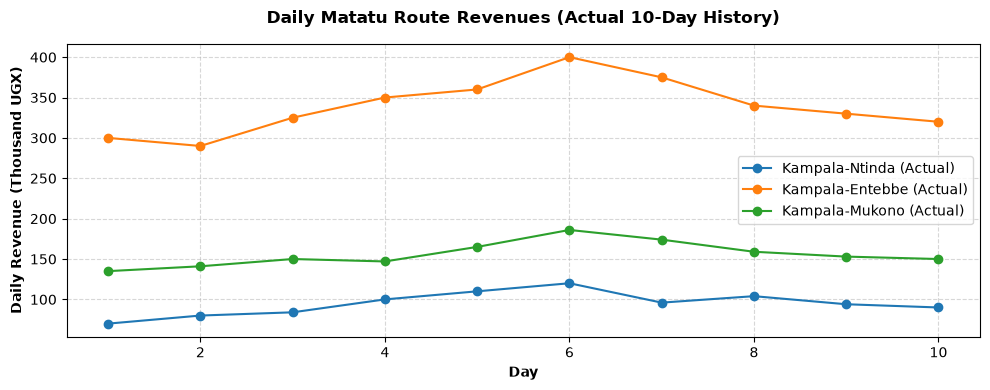

In [4]:
day_11_forecasts = []
actual_vs_pred_plots = {}

for r in routes:
    # Using Linear Trend as the best/robust model
    model = LinearTrendForecaster()
    pred_passengers = model.forecast(r.passengers)
    pred_revenue = pred_passengers * r.fare
    
    day_11_forecasts.append({
        "Route": r.name,
        "Forecast Day 11 Passengers": round(pred_passengers, 1),
        "Forecast Day 11 Revenue (UGX)": f"{pred_revenue:,.2f}"
    })

print("--- Day 11 Forecast Summary ---")
print(pd.DataFrame(day_11_forecasts).to_string(index=False))

# Plotting actual vs forecast revenue comparison
plt.figure(figsize=(10, 4))
days = np.arange(1, 11)
for r in routes:
    plt.plot(days, r.daily_revenue() / 1e3, marker='o', label=f'{r.name} (Actual)')

plt.xlabel('Day', fontweight='bold')
plt.ylabel('Daily Revenue (Thousand UGX)', fontweight='bold')
plt.title('Daily Matatu Route Revenues (Actual 10-Day History)', fontweight='bold', pad=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
# Each vehicle makes 8 one-way trips per day at 14 passengers capacity per trip
# Maximum passenger capacity per vehicle per day = 8 * 14 = 112 passengers
capacity_per_vehicle_day = 8 * 14

fleet_plans = []
for r in routes:
    model = LinearTrendForecaster()
    pred_passengers = model.forecast(r.passengers)
    
    # Raw vehicles needed based on forecast demand
    raw_vehicles = pred_passengers / capacity_per_vehicle_day
    # Apply 15% buffer
    buffered_vehicles = raw_vehicles * 1.15
    # Round sensibly upwards
    deployed_vehicles = int(np.ceil(buffered_vehicles))
    
    fleet_plans.append({
        "Route": r.name,
        "Forecast Passengers": round(pred_passengers, 1),
        "Raw Vehicles": round(raw_vehicles, 2),
        "With 15% Buffer": round(buffered_vehicles, 2),
        "Vehicles to Deploy (Day 11)": deployed_vehicles
    })

print("--- Fleet Deployment Plan for Day 11 ---")
print(pd.DataFrame(fleet_plans).to_string(index=False))

--- Fleet Deployment Plan for Day 11 ---
          Route  Forecast Passengers  Raw Vehicles  With 15% Buffer  Vehicles to Deploy (Day 11)
 Kampala-Ntinda                 53.7          0.48             0.55                            1
Kampala-Entebbe                 72.1          0.64             0.74                            1
 Kampala-Mukono                 56.1          0.50             0.58                            1


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Simulate 60 days of passenger data with a weekly pattern
# (e.g., base demand ~50, Fridays (+15), Sundays (-15), plus minor random noise)
np.random.seed(101)
days_total = 60
base_demand = 50.0
simulated_passengers = []

for d in range(days_total):
    day_of_week = d % 7  # 0: Monday, ..., 4: Friday, 6: Sunday
    weekly_effect = 0.0
    if day_of_week == 4:  # Friday (busier)
        weekly_effect = 18.0
    elif day_of_week == 6:  # Sunday (quieter)
        weekly_effect = -15.0
    
    noise = np.random.normal(0, 4.0)
    val = max(10.0, base_demand + weekly_effect + noise)
    simulated_passengers.append(val)

simulated_passengers = np.array(simulated_passengers)

# 2. Backtest Moving Average vs Seasonal-Naïve over days 7 to 59
ma_forecaster = MovingAverageForecaster(window=7)
seasonal_forecaster = SeasonalNaiveForecaster(seasonal_period=7)

ma_errors = []
seasonal_errors = []

for i in range(7, days_total):
    train = simulated_passengers[:i]
    actual = simulated_passengers[i]
    
    pred_ma = ma_forecaster.forecast(train)
    pred_seasonal = seasonal_forecaster.forecast(train)
    
    ma_errors.append(abs(actual - pred_ma))
    seasonal_errors.append(abs(actual - pred_seasonal))

mae_ma = np.mean(ma_errors)
mae_seasonal = np.mean(seasonal_errors)

print("--- 60-Day Weekly Pattern Simulation Backtest ---")
print(f"Moving Average (7-day window) MAE:     {mae_ma:.2f}")
print(f"Seasonal-Naïve (lag = 7 days) MAE:     {mae_seasonal:.2f}")
print(f"Performance: Seasonal-Naïve beats Moving Average by {(mae_ma - mae_seasonal):.2f} MAE points!")

# 3. Visualisation of 60-day demand with weekly seasonality
plt.figure(figsize=(12, 5))
plt.plot(np.arange(1, days_total + 1), simulated_passengers, marker='o', markersize=4, color='teal', label='Simulated Daily Demand')
plt.xlabel('Day', fontweight='bold')
plt.ylabel('Passenger Count', fontweight='bold')
plt.title('60-Day Matatu Passenger Demand with Weekly Seasonality (Peaks on Fridays, Troughs on Sundays)', fontweight='bold', pad=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'SeasonalNaiveForecaster' is not defined